In [1]:
%load_ext autoreload
%autoreload 2

import torch
from attention import TinyGPT
from data_gathering import gather_data, format_data
from training import train, generate_text, uniform_random_loss, evaluate_lm
torch.manual_seed(42)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(torch.__version__, "| CUDA:", torch.cuda.is_available())

2.11.0+cu128 | CUDA: True


In [2]:
# Fetches Wikipedia pages, Gutenberg books, and Shakespeare corpus.
# Pass custom lists to override the defaults (see attention.py).
# text = gather_data()

with open("dog_corpus.txt", "r", encoding="utf-8") as f:
    text = f.read()


In [3]:
seq_len = 64
input_ids, target_ids, vocab, stoi, itos = format_data(text, seq_len=seq_len)

Vocab size : 11,630
Sequences  : 584,026  (seq_len=64)
<unk> rate : 4.52%


In [4]:
input_ids  = input_ids.to(device)
target_ids = target_ids.to(device)

split_idx = int(0.9 * input_ids.size(0))
train_input_ids,  val_input_ids  = input_ids[:split_idx],  input_ids[split_idx:]
train_target_ids, val_target_ids = target_ids[:split_idx], target_ids[split_idx:]

print("Train:", train_input_ids.shape, "| Val:", val_input_ids.shape)

Train: torch.Size([525623, 64]) | Val: torch.Size([58403, 64])


In [5]:
model = TinyGPT(
    vocab_size=len(vocab),
    d_model=128,
    hidden_dim=1024,
    num_layers=4,
    max_len=seq_len,
    dropout=0.1
).to(device)


print(f"Parameters: {sum(p.numel() for p in model.parameters()):,}")

Parameters: 2,808,320


In [6]:
uniform = uniform_random_loss(len(vocab))

print(f"Vocab size:            {len(vocab):,}")
print(f"Uniform random loss:   {uniform:.4f}   (knows nothing)")


Vocab size:            11,630
Uniform random loss:   9.3613   (knows nothing)


In [7]:
sequences   = 506_592
seq_len     = 64
dtype_bytes = 4       # int32
tensors     = 4       # train_input, train_target, val_input, val_target

total_mb = sequences * seq_len * dtype_bytes * tensors / 1e6
print(f"~{total_mb:.0f} MB just for the data tensors")

~519 MB just for the data tensors


In [8]:
for name, t in [("train_input", train_input_ids), ("train_target", train_target_ids),
                ("val_input", val_input_ids), ("val_target", val_target_ids)]:
    print(f"{name}: {t.shape}  {t.element_size() * t.numel() / 1e6:.1f} MB")

# model memory
param_mb = sum(p.element_size() * p.numel() for p in model.parameters()) / 1e6
print(f"\nModel params: {param_mb:.1f} MB")
print(f"AdamW buffers (est): {param_mb * 2:.1f} MB")

train_input: torch.Size([525623, 64])  269.1 MB
train_target: torch.Size([525623, 64])  269.1 MB
val_input: torch.Size([58403, 64])  29.9 MB
val_target: torch.Size([58403, 64])  29.9 MB

Model params: 11.2 MB
AdamW buffers (est): 22.5 MB



Epoch 01/5
-----------------------------------------------------------------
  batch   1000/32852 | loss 8.8417  acc 0.0408 | lr 1.83e-05
  batch   2000/32852 | loss 6.9845  acc 0.0614 | lr 3.65e-05
  batch   3000/32852 | loss 6.3509  acc 0.0612 | lr 5.48e-05
  batch   4000/32852 | loss 6.3543  acc 0.0648 | lr 7.31e-05
  batch   5000/32852 | loss 6.1840  acc 0.0930 | lr 9.13e-05
  batch   6000/32852 | loss 5.9711  acc 0.1151 | lr 1.10e-04
  batch   7000/32852 | loss 5.8403  acc 0.1224 | lr 1.28e-04
  batch   8000/32852 | loss 5.7565  acc 0.1264 | lr 1.46e-04
  batch   9000/32852 | loss 5.6569  acc 0.1321 | lr 1.64e-04
  batch  10000/32852 | loss 5.5589  acc 0.1380 | lr 1.83e-04
  batch  11000/32852 | loss 5.4754  acc 0.1453 | lr 2.01e-04
  batch  12000/32852 | loss 5.3878  acc 0.1555 | lr 2.19e-04
  batch  13000/32852 | loss 5.3128  acc 0.1636 | lr 2.37e-04
  batch  14000/32852 | loss 5.2393  acc 0.1691 | lr 2.56e-04
  batch  15000/32852 | loss 5.1808  acc 0.1731 | lr 2.74e-04
  batch

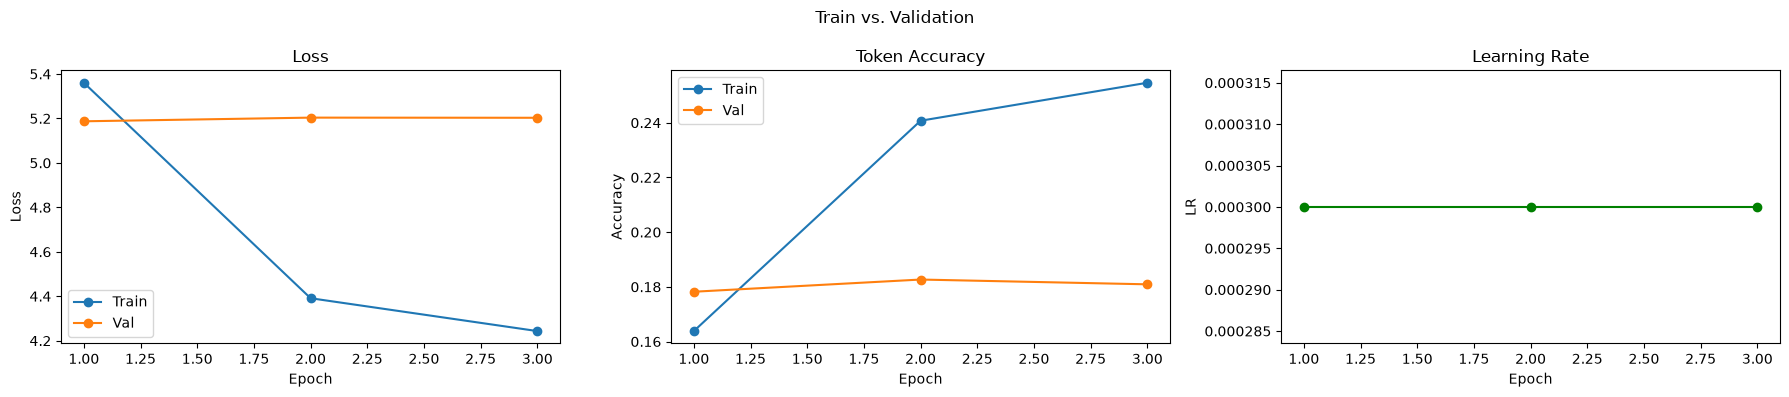

In [9]:
train_losses, val_losses, train_accs, val_accs = train(
    model,
    train_input_ids, train_target_ids,
    val_input_ids,   val_target_ids,
    num_epochs=5,
    batch_size=16,
    device=device,
    weight_decay=0.01,
    lr = 3e-4,
    log_every = 1000

)

In [10]:
prompt = "Maki is so predator"
print(generate_text(model, prompt, stoi, itos, seq_len, device, max_new_tokens=7))

is so predator to the wolf s range and the


In [11]:
checkpoint = torch.load("checkpoints/best.pt")
model.load_state_dict(checkpoint["model_state"])

metrics = evaluate_lm(
    model,
    val_input_ids, val_target_ids,
    vocab,
    train_target_ids=train_target_ids,   # needed for the unigram baseline
    device=device,
)

LANGUAGE MODEL EVALUATION

Vocab size:              11,630

── Your model ──
Validation loss:         5.1872 nats
Validation perplexity:   179.0
Token accuracy:          17.82%  (next word exactly right)

── Baselines (what you're beating) ──
Uniform random loss:     9.3613  (perplexity 11,630)
  → knows nothing, picks any of 11,630 words equally
Unigram loss:            6.3375  (perplexity 565)
  → knows word frequencies, but ignores all context

── Interpretation ──
Your model effectively chooses between ~179 words per step,
instead of 11,630 (random) — it closed 44.6% of the
gap from random toward perfect prediction.

✓ It beats the unigram baseline by 1.15 nats —
  meaning it genuinely USES CONTEXT, not just word frequency.
